## Earthquake Damage Prediction

## Project Overview

In this project, we will analyze building data and predict the level of damage a building may receive during an earthquake using Machine Learning.

### What we will do in this project:

1. **Understand the Dataset**
   - Load the dataset.
   - Understand rows, columns, features, and target variable.

2. **Data Cleaning**
   - Check missing values.
   - Check duplicate records.
   - Check data types and data quality.

3. **Exploratory Data Analysis (EDA)**
   - Analyze the target variable.
   - Study important building features.
   - Use charts and graphs to understand patterns and relationships.

4. **Feature Engineering & Preprocessing**
   - Prepare the data for Machine Learning.
   - Convert categorical data into numerical form.
   - Apply suitable preprocessing techniques.

5. **Build Machine Learning Models**
   - Split the data into training and testing sets.
   - Train multiple Machine Learning models to predict `damage_grade`.

6. **Model Evaluation & Comparison**
   - Evaluate the models using suitable performance metrics.
   - Compare the model results.

7. **Hyperparameter Tuning**
   - Improve the selected models by finding suitable parameters.

8. **Feature Importance & Interpretation**
   - Identify which building characteristics are important for predicting earthquake damage.

9. **Suggestions**
   - Based on our analysis, provide suggestions that may help reduce significant building damage during earthquakes.

10. **Final Conclusion**
   - Summarize the analysis, model performance, important findings, challenges, and final results.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
train_values = pd.read_csv("train_values.csv")
train_labels = pd.read_csv("train_labels.csv")

In [3]:
print("Train values shape:", train_values.shape)
print("Train labels shape:", train_labels.shape)

Train values shape: (260601, 39)
Train labels shape: (260601, 2)


In [4]:
train_values.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,0


In [5]:
train_labels.head()

,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


In [6]:
df = train_values.merge(train_labels, on="building_id", how="inner")

In [7]:
print("Final dataset shape:", df.shape)

Final dataset shape: (260601, 40)


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype 
---  ------                                  --------------   ----- 
 0   building_id                             260601 non-null  int64 
 1   geo_level_1_id                          260601 non-null  int64 
 2   geo_level_2_id                          260601 non-null  int64 
 3   geo_level_3_id                          260601 non-null  int64 
 4   count_floors_pre_eq                     260601 non-null  int64 
 5   age                                     260601 non-null  int64 
 6   area_percentage                         260601 non-null  int64 
 7   height_percentage                       260601 non-null  int64 
 8   land_surface_condition                  260601 non-null  object
 9   foundation_type                         260601 non-null  object
 10  roof_type                               260601 non-null 

In [9]:
df.isnull().sum()

building_id                               0
geo_level_1_id                            0
geo_level_2_id                            0
geo_level_3_id                            0
count_floors_pre_eq                       0
age                                       0
area_percentage                           0
height_percentage                         0
land_surface_condition                    0
foundation_type                           0
roof_type                                 0
ground_floor_type                         0
other_floor_type                          0
position                                  0
plan_configuration                        0
has_superstructure_adobe_mud              0
has_superstructure_mud_mortar_stone       0
has_superstructure_stone_flag             0
has_superstructure_cement_mortar_stone    0
has_superstructure_mud_mortar_brick       0
has_superstructure_cement_mortar_brick    0
has_superstructure_timber                 0
has_superstructure_bamboo       

In [10]:
df.duplicated().sum()

np.int64(0)

# data cleaning

In [11]:
df.describe()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
count,2.606010e+05,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,...,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000
mean,5.256755e+05,13.900353,701.074685,6257.876148,2.129723,26.535029,8.018051,5.434365,0.088645,0.761935,...,0.033626,0.008101,0.000940,0.000361,0.001071,0.000188,0.000146,0.000088,0.005119,2.238272
std,3.045450e+05,8.033617,412.710734,3646.369645,0.727665,73.565937,4.392231,1.918418,0.284231,0.425900,...,0.180265,0.089638,0.030647,0.018989,0.032703,0.013711,0.012075,0.009394,0.071364,0.611814
min,4.000000e+00,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.611900e+05,7.000000,350.000000,3073.000000,2.000000,10.000000,5.000000,4.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,5.257570e+05,12.000000,702.000000,6270.000000,2.000000,15.000000,7.000000,5.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,7.897620e+05,21.000000,1050.000000,9412.000000,2.000000,30.000000,9.000000,6.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,1.052934e+06,30.000000,1427.000000,12567.000000,9.000000,995.000000,100.000000,32.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000


In [12]:
categorical_columns = df.select_dtypes(include="object").columns
print(categorical_columns)

Index(['land_surface_condition', 'foundation_type', 'roof_type',
       'ground_floor_type', 'other_floor_type', 'position',
       'plan_configuration', 'legal_ownership_status'],
      dtype='object')


In [13]:
for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())


 land_surface_condition
land_surface_condition
t    216757
n     35528
o      8316
Name: count, dtype: int64

 foundation_type
foundation_type
r    219196
w     15118
u     14260
i     10579
h      1448
Name: count, dtype: int64

 roof_type
roof_type
n    182842
q     61576
x     16183
Name: count, dtype: int64

 ground_floor_type
ground_floor_type
f    209619
x     24877
v     24593
z      1004
m       508
Name: count, dtype: int64

 other_floor_type
other_floor_type
q    165282
x     43448
j     39843
s     12028
Name: count, dtype: int64

 position
position
s    202090
t     42896
j     13282
o      2333
Name: count, dtype: int64

 plan_configuration
plan_configuration
d    250072
q      5692
u      3649
s       346
c       325
a       252
o       159
m        46
n        38
f        22
Name: count, dtype: int64

 legal_ownership_status
legal_ownership_status
v    250939
a      5512
w      2677
r      1473
Name: count, dtype: int64


In [14]:
for col in categorical_columns:
    print(col,":",df[col].unique())

land_surface_condition : ['t' 'o' 'n']
foundation_type : ['r' 'w' 'i' 'u' 'h']
roof_type : ['n' 'q' 'x']
ground_floor_type : ['f' 'x' 'v' 'z' 'm']
other_floor_type : ['q' 'x' 'j' 's']
position : ['t' 's' 'j' 'o']
plan_configuration : ['d' 'u' 's' 'q' 'm' 'c' 'a' 'n' 'f' 'o']
legal_ownership_status : ['v' 'a' 'r' 'w']


In [15]:
df["building_id"].duplicated().sum()

np.int64(0)

In [16]:
numeric_cols = df.select_dtypes(include=np.number).columns
print(numeric_cols)
print("Total numerical columns:", len(numeric_cols))

Index(['building_id', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id',
       'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage',
       'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone',
       'has_superstructure_stone_flag',
       'has_superstructure_cement_mortar_stone',
       'has_superstructure_mud_mortar_brick',
       'has_superstructure_cement_mortar_brick', 'has_superstructure_timber',
       'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered',
       'has_superstructure_rc_engineered', 'has_superstructure_other',
       'count_families', 'has_secondary_use', 'has_secondary_use_agriculture',
       'has_secondary_use_hotel', 'has_secondary_use_rental',
       'has_secondary_use_institution', 'has_secondary_use_school',
       'has_secondary_use_industry', 'has_secondary_use_health_post',
       'has_secondary_use_gov_office', 'has_secondary_use_use_police',
       'has_secondary_use_other', 'damage_grade'],
      dt

In [17]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
building_id,260601.0,525675.482773,304544.999032,4.0,261190.0,525757.0,789762.0,1052934.0
geo_level_1_id,260601.0,13.900353,8.033617,0.0,7.0,12.0,21.0,30.0
geo_level_2_id,260601.0,701.074685,412.710734,0.0,350.0,702.0,1050.0,1427.0
geo_level_3_id,260601.0,6257.876148,3646.369645,0.0,3073.0,6270.0,9412.0,12567.0
count_floors_pre_eq,260601.0,2.129723,0.727665,1.0,2.0,2.0,2.0,9.0
age,260601.0,26.535029,73.565937,0.0,10.0,15.0,30.0,995.0
area_percentage,260601.0,8.018051,4.392231,1.0,5.0,7.0,9.0,100.0
height_percentage,260601.0,5.434365,1.918418,2.0,4.0,5.0,6.0,32.0
has_superstructure_adobe_mud,260601.0,0.088645,0.284231,0.0,0.0,0.0,0.0,1.0
has_superstructure_mud_mortar_stone,260601.0,0.761935,0.425900,0.0,1.0,1.0,1.0,1.0


In [18]:
df["age"].value_counts().sort_index().tail(20)

age
110     100
115      21
120     180
125      37
130       9
135       5
140       9
145       3
150     142
155       1
160       6
165       2
170       6
175       5
180       7
185       1
190       3
195       2
200     106
995    1390
Name: count, dtype: int64

In [19]:
binary_cols = [col for col in df.columns if col.startswith("has_")]
print("Total binary columns:", len(binary_cols))
print(binary_cols)


Total binary columns: 22
['has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other']


In [20]:
for col in binary_cols:
    print(col,":",df[col].unique())

has_superstructure_adobe_mud : [1 0]
has_superstructure_mud_mortar_stone : [1 0]
has_superstructure_stone_flag : [0 1]
has_superstructure_cement_mortar_stone : [0 1]
has_superstructure_mud_mortar_brick : [0 1]
has_superstructure_cement_mortar_brick : [0 1]
has_superstructure_timber : [0 1]
has_superstructure_bamboo : [0 1]
has_superstructure_rc_non_engineered : [0 1]
has_superstructure_rc_engineered : [0 1]
has_superstructure_other : [0 1]
has_secondary_use : [0 1]
has_secondary_use_agriculture : [0 1]
has_secondary_use_hotel : [0 1]
has_secondary_use_rental : [0 1]
has_secondary_use_institution : [0 1]
has_secondary_use_school : [0 1]
has_secondary_use_industry : [0 1]
has_secondary_use_health_post : [0 1]
has_secondary_use_gov_office : [0 1]
has_secondary_use_use_police : [0 1]
has_secondary_use_other : [0 1]


In [21]:
df["damage_grade"].value_counts().sort_index()

damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64

In [22]:
df["damage_grade"].value_counts(normalize=True).sort_index() * 100

damage_grade
1     9.640792
2    56.891186
3    33.468022
Name: proportion, dtype: float64

In [23]:
numeric_cols = df.select_dtypes(include=np.number).columns

outlier_cols = [ col for col in numeric_cols
                  if col not in ["building_id","damage_grade"]
                 and df[col].nunique() > 2]
print("cols for outlier checking:")
print(outlier_cols)
print("Total:", len(outlier_cols))


cols for outlier checking:
['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']
Total: 8


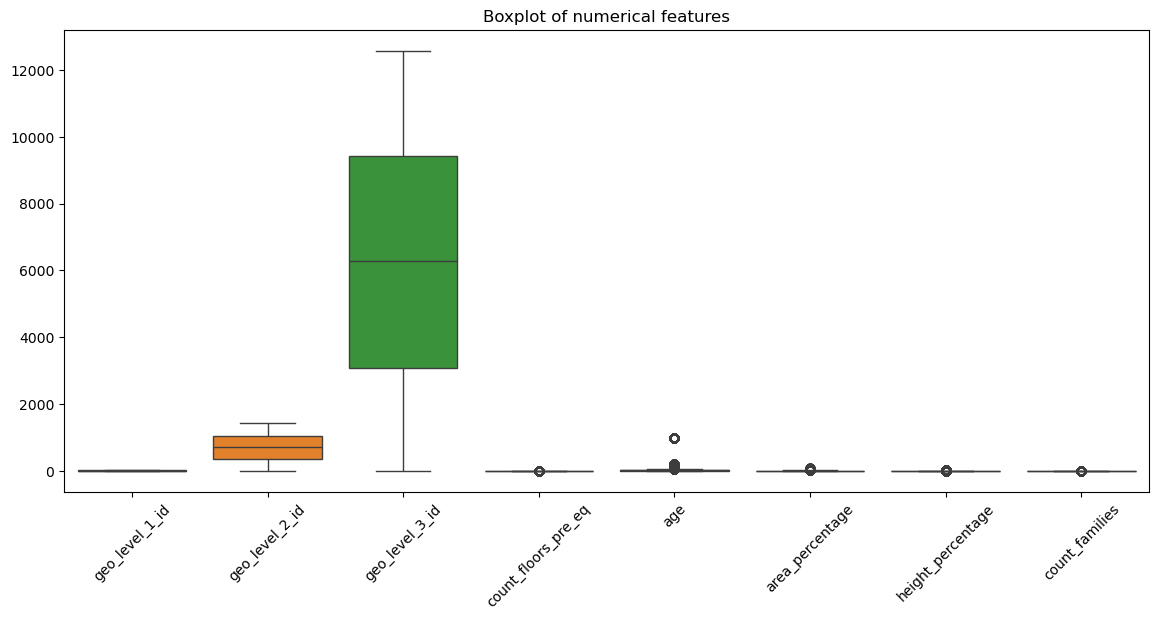

In [24]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df[outlier_cols])
plt.xticks(rotation=45)
plt.title("Boxplot of numerical features")
plt.show()

In [25]:
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR= Q3-Q1

    lower= Q1-1.5 * IQR
    upper= Q3+1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(col,":", len(outliers))

geo_level_1_id : 0
geo_level_2_id : 0
geo_level_3_id : 0
count_floors_pre_eq : 103978
age : 12499
area_percentage : 13557
height_percentage : 7843
count_families : 34486


In [26]:
for col in categorical_columns:
    print(col,"\n")
    print(df[col].value_counts())

land_surface_condition 

land_surface_condition
t    216757
n     35528
o      8316
Name: count, dtype: int64
foundation_type 

foundation_type
r    219196
w     15118
u     14260
i     10579
h      1448
Name: count, dtype: int64
roof_type 

roof_type
n    182842
q     61576
x     16183
Name: count, dtype: int64
ground_floor_type 

ground_floor_type
f    209619
x     24877
v     24593
z      1004
m       508
Name: count, dtype: int64
other_floor_type 

other_floor_type
q    165282
x     43448
j     39843
s     12028
Name: count, dtype: int64
position 

position
s    202090
t     42896
j     13282
o      2333
Name: count, dtype: int64
plan_configuration 

plan_configuration
d    250072
q      5692
u      3649
s       346
c       325
a       252
o       159
m        46
n        38
f        22
Name: count, dtype: int64
legal_ownership_status 

legal_ownership_status
v    250939
a      5512
w      2677
r      1473
Name: count, dtype: int64


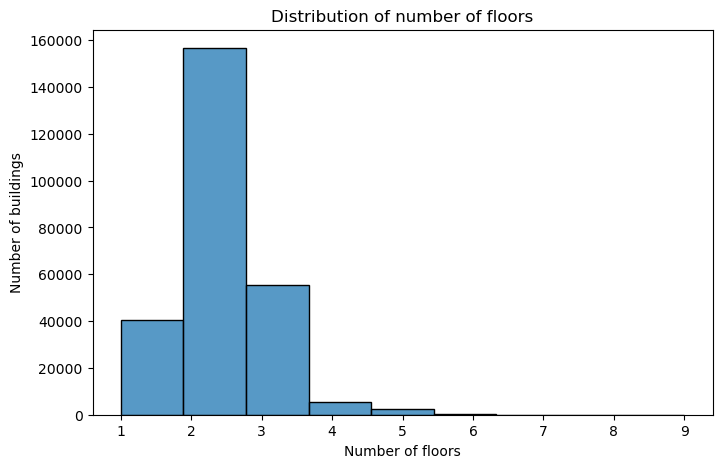

In [27]:
plt.figure(figsize=(8,5))

sns.histplot(df["count_floors_pre_eq"], bins=9)
plt.title("Distribution of number of floors")
plt.xlabel("Number of floors")
plt.ylabel("Number of buildings")

plt.show()

Most buildings in the dataset have 2 floors. The number of buildings decreases as the number of floors increases. Buildings with 6 to 9 floors are very few.
This is univariate analysis because we check only one feature.

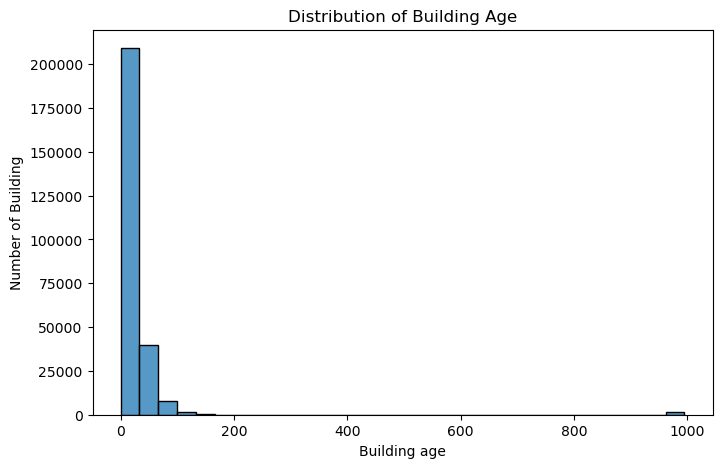

In [28]:
plt.figure(figsize=(8,5))
sns.histplot(df["age"], bins=30)

plt.title("Distribution of Building Age")
plt.xlabel("Building age")
plt.ylabel("Number of Building")

plt.show()

Most buildings have an age below 100 years. A small number of buildings have very high age values, close to 1000 years, which can be considered potential outliers and should be investigated further.

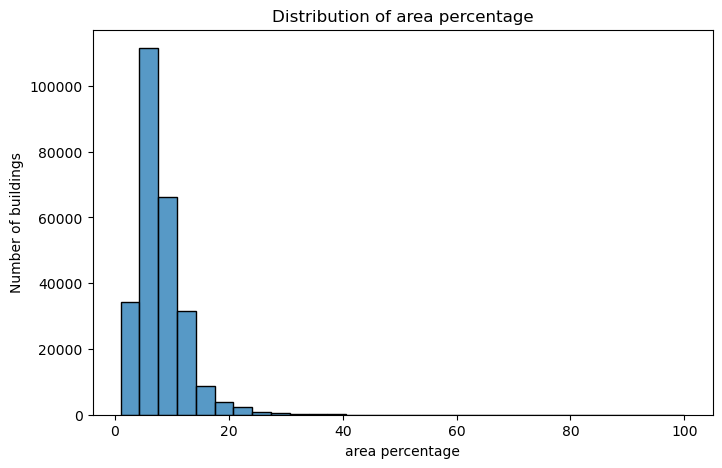

In [29]:
plt.figure(figsize=(8,5))
sns.histplot(df["area_percentage"], bins=30)

plt.title("Distribution of area percentage")
plt.xlabel("area percentage")
plt.ylabel("Number of buildings")

plt.show()

Most buildings have a low area percentage, mainly around 5 to 10%. The frequency decreases as the area percentage increases, resulting in a right-skewed distribution

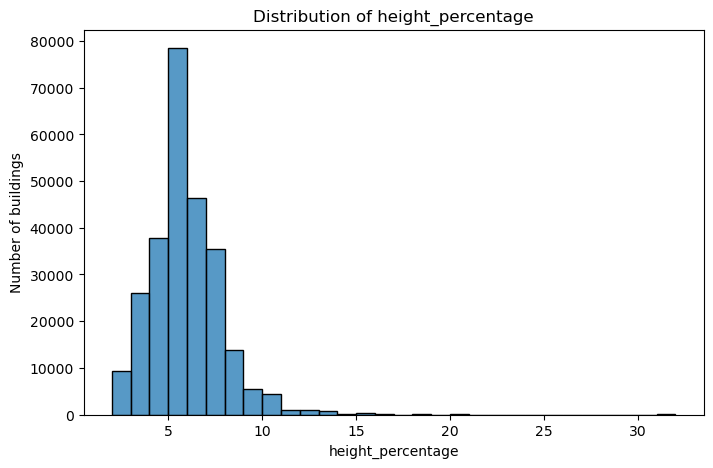

In [30]:
plt.figure(figsize=(8,5))
sns.histplot(df["height_percentage"], bins=30)

plt.title("Distribution of height_percentage")
plt.xlabel("height_percentage")
plt.ylabel("Number of buildings")

plt.show()

Most buildings have a height percentage between approximately 4 and 8%. The frequency decreases as height percentage increases, and there are very few buildings with high height percentages.

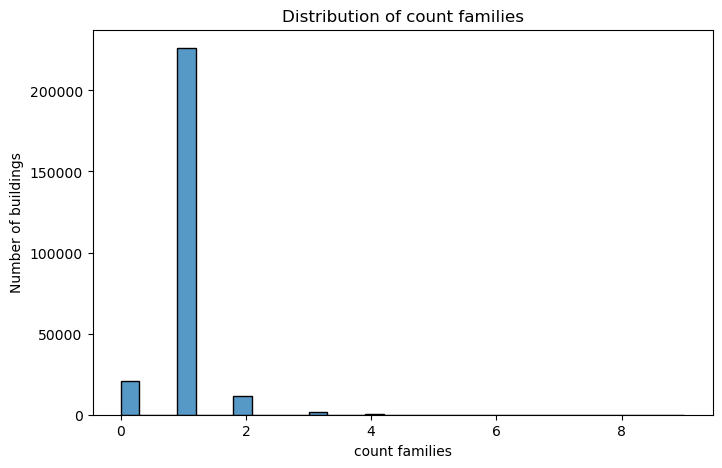

In [31]:
plt.figure(figsize=(8,5))
sns.histplot(df["count_families"], bins=30)

plt.title("Distribution of count families")
plt.xlabel("count families")
plt.ylabel("Number of buildings")

plt.show()

Most buildings have one family. Buildings with two or more families are much fewer, and the frequency decreases as the number of families increases.

In [32]:
# Analyse categorical features

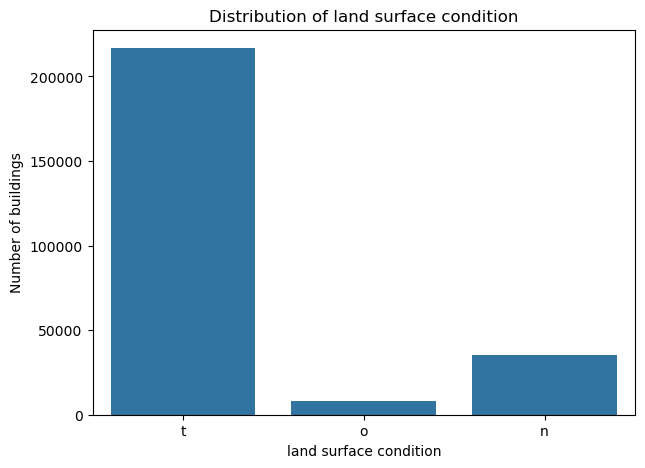

In [33]:
plt.figure(figsize=(7,5))
sns.countplot(x=df["land_surface_condition"])

plt.title("Distribution of land surface condition")
plt.xlabel("land surface condition")
plt.ylabel("Number of buildings")
plt.show()

The t category is the most common, followed by n, while o is the least common. The categories are represented by obfuscated codes

Numerical data → histplot()
Categorical data → countplot()

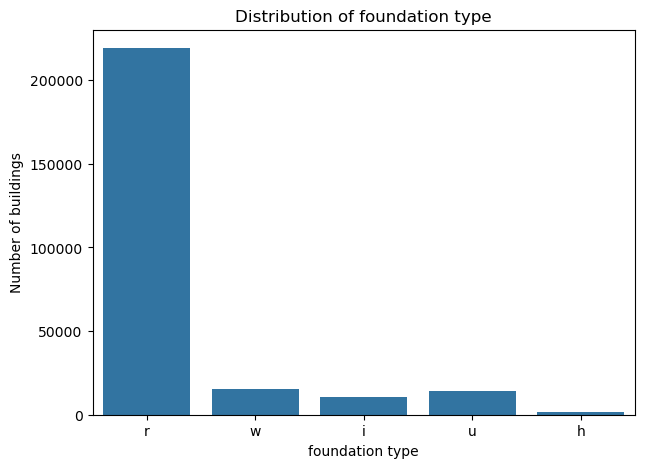

In [34]:
plt.figure(figsize=(7,5))
sns.countplot(x=df["foundation_type"])

plt.title("Distribution of foundation type")
plt.xlabel("foundation type")
plt.ylabel("Number of buildings")

plt.show()

The r category is highly dominant, while h is the least frequent category. The remaining categories have relatively fewer observations.

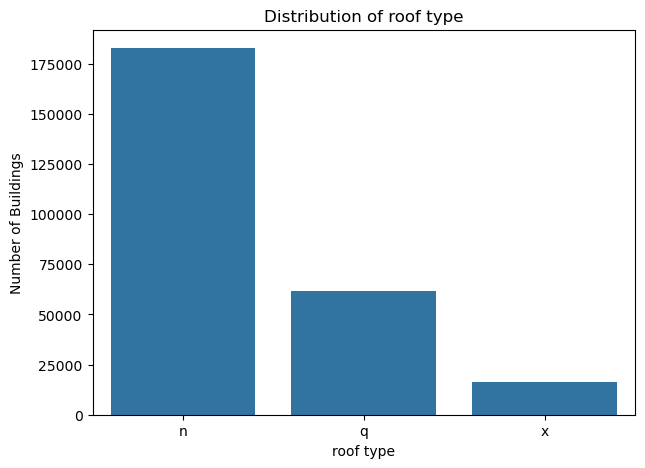

In [35]:
plt.figure(figsize=(7,5))
sns.countplot(x=df["roof_type"])

plt.title("Distribution of roof type")
plt.xlabel("roof type")
plt.ylabel("Number of Buildings")

plt.show()

The n category is the most common roof type category, followed by q. The x category has the fewest observations.

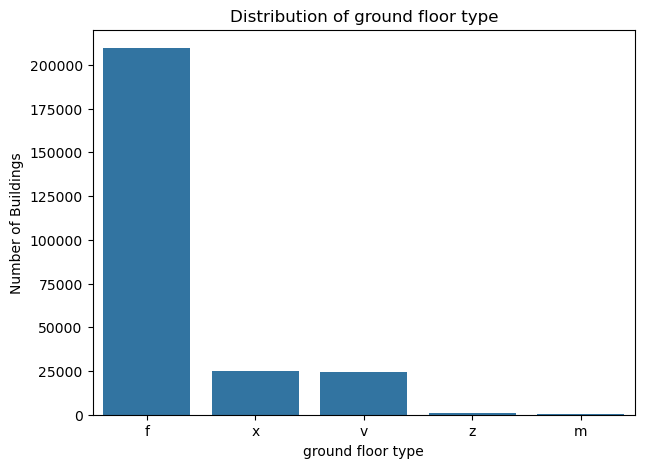

In [36]:
plt.figure(figsize=(7,5))
sns.countplot(x=df["ground_floor_type"])

plt.title("Distribution of ground floor type")
plt.xlabel("ground floor type")
plt.ylabel("Number of Buildings")

plt.show()

The f category is highly dominant, while m is the least frequent. The x and v categories have similar frequencies.

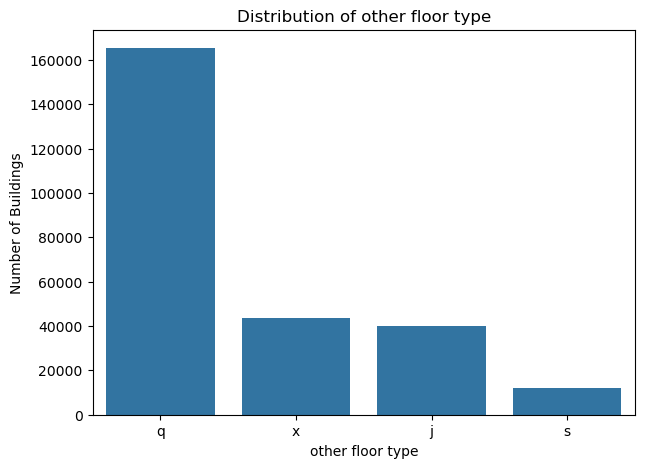

In [37]:
plt.figure(figsize=(7,5))
sns.countplot(x=df["other_floor_type"])

plt.title("Distribution of other floor type")
plt.xlabel("other floor type")
plt.ylabel("Number of Buildings")

plt.show()

The q category is the most common, followed by x and j. The s category has the fewest observations.

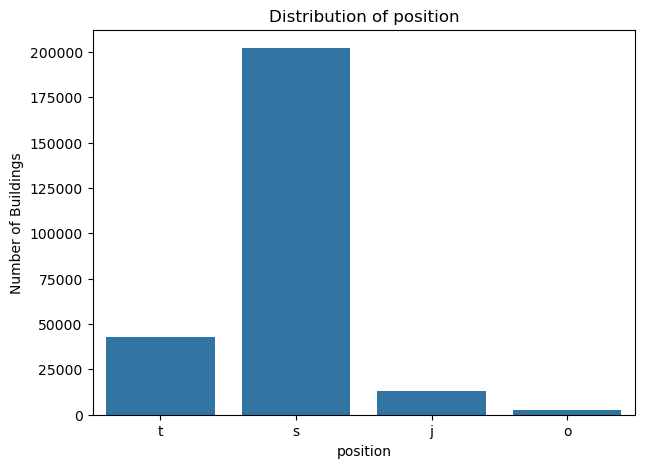

In [38]:
plt.figure(figsize=(7,5))
sns.countplot(x=df["position"])

plt.title("Distribution of position")
plt.xlabel("position")
plt.ylabel("Number of Buildings")

plt.show()

The s category is highly dominant, followed by t. The o category has the fewest observations.

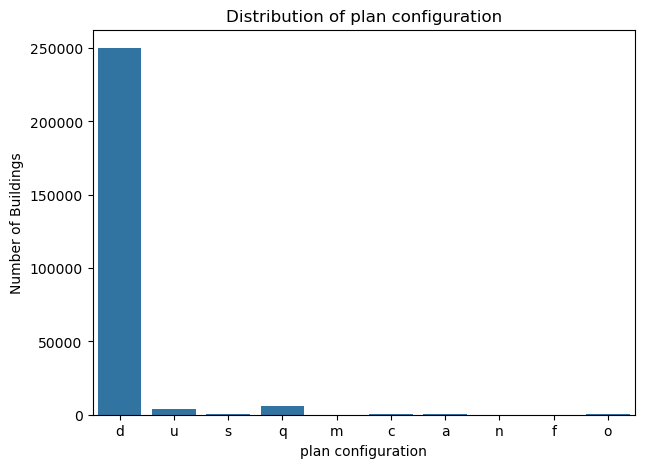

In [39]:
plt.figure(figsize=(7,5))
sns.countplot(x=df["plan_configuration"])

plt.title("Distribution of plan configuration")
plt.xlabel("plan configuration")
plt.ylabel("Number of Buildings")

plt.show()

The d category is highly dominant in plan configuration, while most other categories are relatively rare.

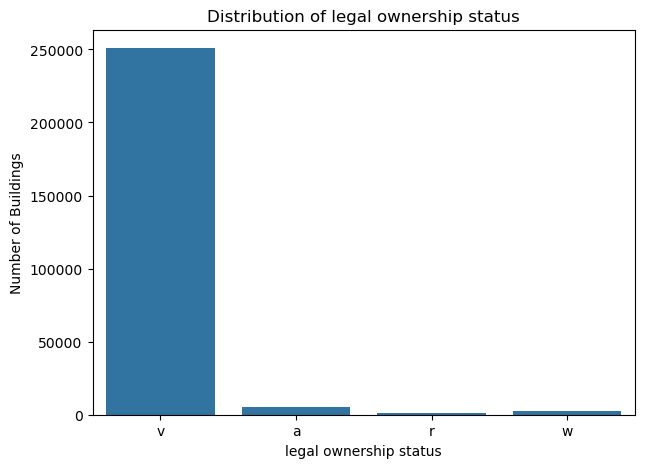

In [40]:
plt.figure(figsize=(7,5))
sns.countplot(x=df["legal_ownership_status"])

plt.title("Distribution of legal ownership status")
plt.xlabel("legal ownership status")
plt.ylabel("Number of Buildings")

plt.show()

The v category is highly dominant, while r is the least frequent category. The other categories have relatively few observations

## damage grade target distribution

It checks target variable is balanced or not

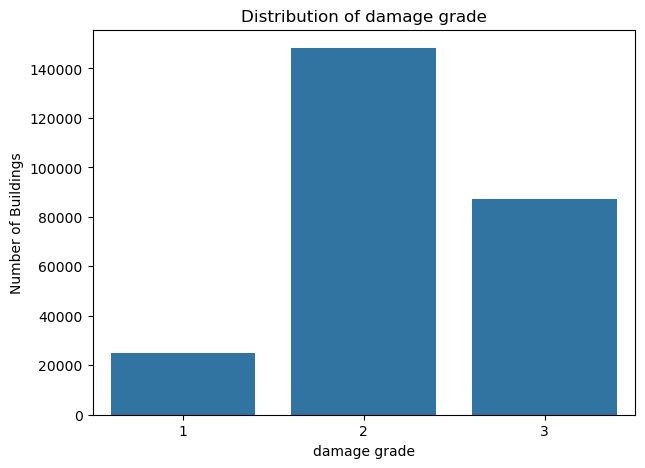

In [41]:
plt.figure(figsize=(7,5))
sns.countplot(x=df["damage_grade"])

plt.title("Distribution of damage grade")
plt.xlabel("damage grade")
plt.ylabel("Number of Buildings")

plt.show()

Damage Grade 2 is the most common class, followed by Grade 3, while Grade 1 has the fewest observations. Therefore, the target variable is imbalanced.

## Bivariate EDA

In [42]:
# check relation between two variables

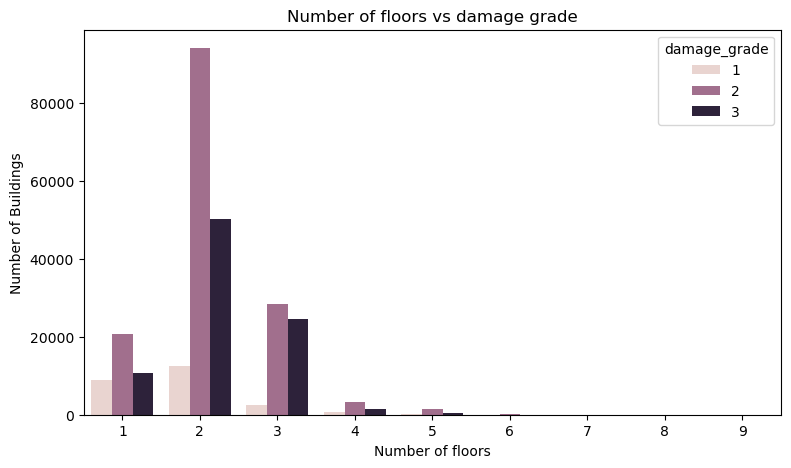

In [43]:
plt.figure(figsize=(9,5))

sns.countplot(
    x="count_floors_pre_eq",
    hue="damage_grade",
    data=df
)
plt.title("Number of floors vs damage grade")
plt.xlabel("Number of floors")
plt.ylabel("Number of Buildings")

plt.show()

The countplot shows that damage grade 2 has the highest number of observations across most floor categories. However, because the number of buildings differs across floor categories, proportions should be compared before concluding a relationship

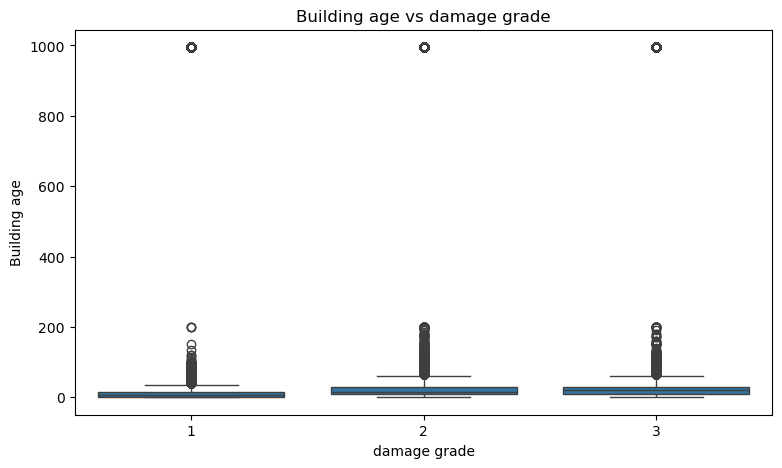

In [44]:
plt.figure(figsize=(9,5))

sns.boxplot(x="damage_grade", y="age", data=df)
plt.title("Building age vs damage grade")
plt.xlabel("damage grade")
plt.ylabel("Building age")
plt.show()

The boxplot shows that buildings with higher damage grades tend to have a higher age distribution. Several high-age outliers are also present across all damage grades

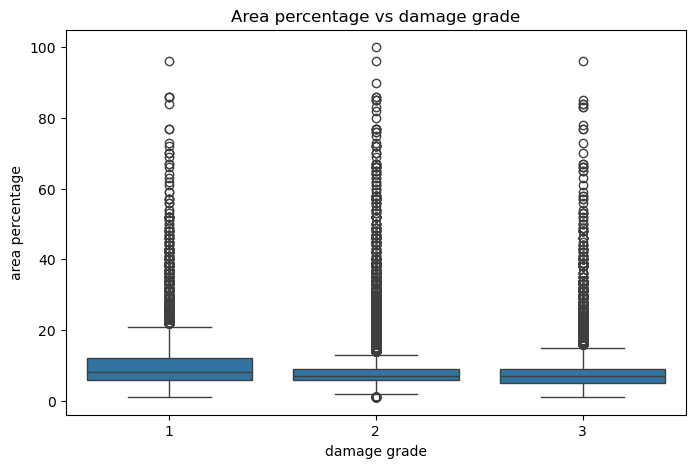

In [45]:
plt.figure(figsize=(8,5))
sns.boxplot(x="damage_grade", y="area_percentage", data=df)

plt.title("Area percentage vs damage grade")
plt.xlabel("damage grade")
plt.ylabel("area percentage")

plt.show()

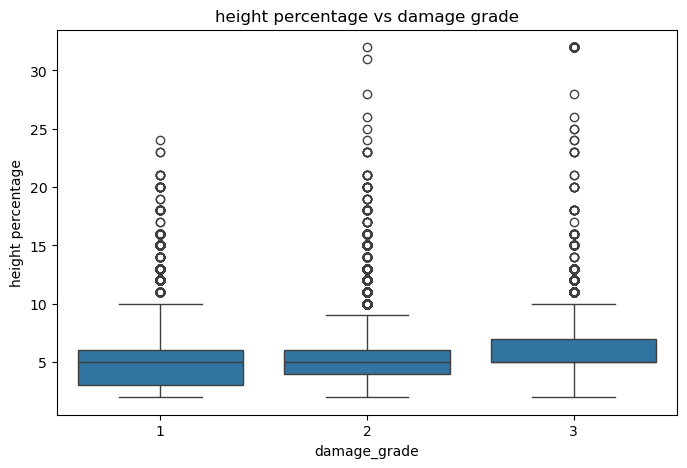

In [46]:
plt.figure(figsize=(8,5))
sns.boxplot(x="damage_grade", y="height_percentage", data=df)

plt.title("height percentage vs damage grade")
plt.xlabel("damage_grade")
plt.ylabel("height percentage")

plt.show()

The boxplot shows that Grade 3 buildings generally have a higher height percentage compared with Grades 1 and 2. All three damage grades contain some high-value outliers.

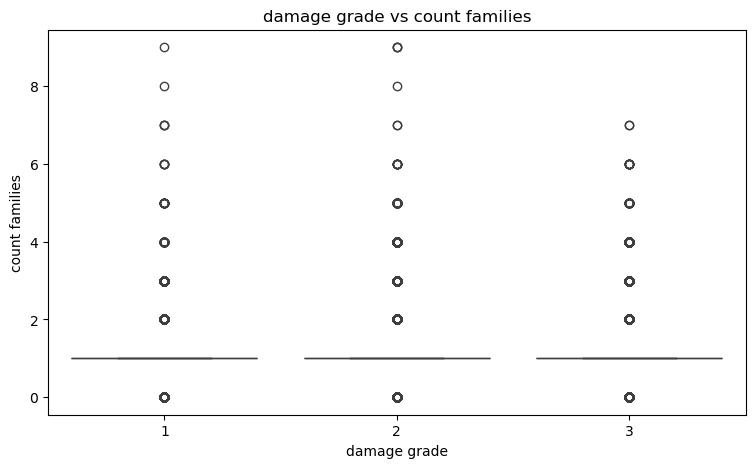

In [47]:
plt.figure(figsize=(9,5))
sns.boxplot(x="damage_grade", y="count_families", data=df)

plt.title("damage grade vs count families")
plt.xlabel("damage grade")
plt.ylabel("count families")
plt.show()

The median number of families is approximately one across all damage grades. Higher family counts appear as outliers, and there is no strong visible difference in the distribution across damage grades.

## categorical features vs damage grade

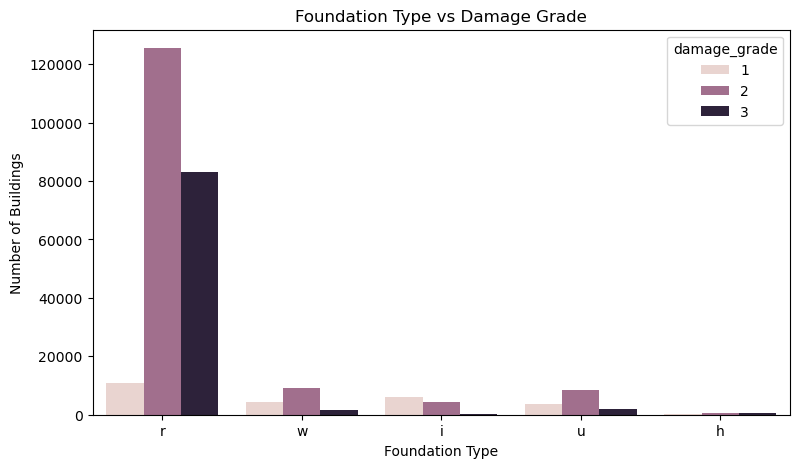

In [48]:
plt.figure(figsize=(9, 5))

sns.countplot(
    x="foundation_type",
    hue="damage_grade",    #Hue is used to add another categorical variable to a plot and differentiate its categories using different colors.
    data=df
)

plt.title("Foundation Type vs Damage Grade")
plt.xlabel("Foundation Type")
plt.ylabel("Number of Buildings")

plt.show()

Grade 2 is the most frequent damage grade for foundation categories r, w, and u. For i, Grade 1 is more frequent, while h shows a more similar distribution.

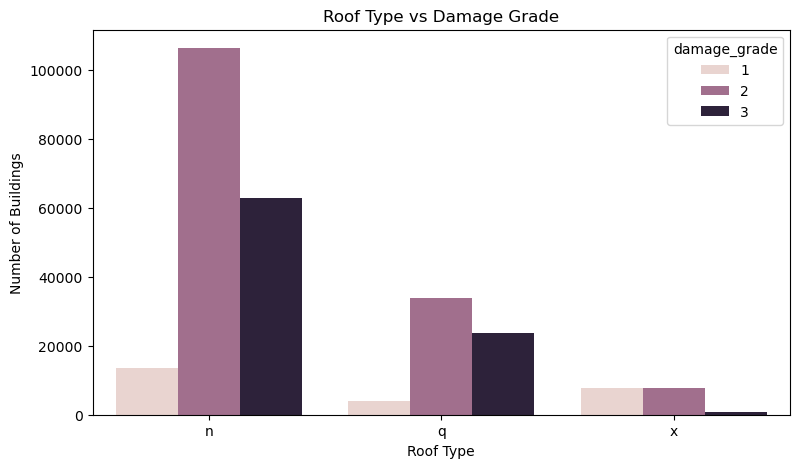

In [49]:
plt.figure(figsize=(9, 5))

sns.countplot(
    x="roof_type",
    hue="damage_grade",
    data=df
)

plt.title("Roof Type vs Damage Grade")
plt.xlabel("Roof Type")
plt.ylabel("Number of Buildings")

plt.show()

For roof categories n and q, Grade 2 has the highest frequency. For category x, the frequencies of Grade 1 and Grade 2 are approximately similar.

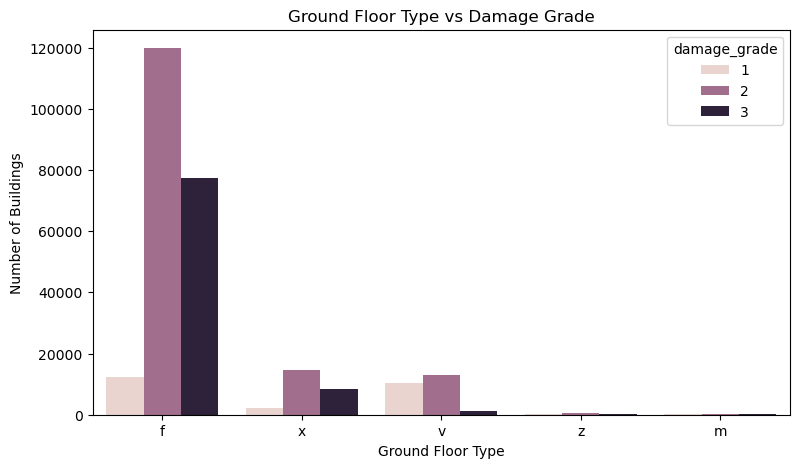

In [50]:
plt.figure(figsize=(9, 5))

sns.countplot(
    x="ground_floor_type",
    hue="damage_grade",
    data=df
)

plt.title("Ground Floor Type vs Damage Grade")
plt.xlabel("Ground Floor Type")
plt.ylabel("Number of Buildings")

plt.show()

For all ground floor type categories, Damage Grade 2 has the highest frequency. This shows an association in the dataset, but it does not prove that ground floor type causes the damage.

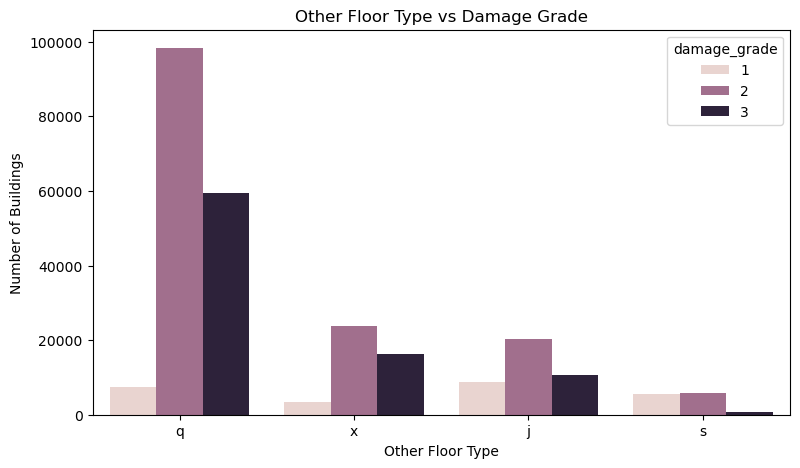

In [51]:
plt.figure(figsize=(9, 5))

sns.countplot(
    x="other_floor_type",
    hue="damage_grade",
    data=df
)

plt.title("Other Floor Type vs Damage Grade")
plt.xlabel("Other Floor Type")
plt.ylabel("Number of Buildings")
plt.show()

For q, x, and j categories, Damage Grade 2 has the highest frequency. For category s, Grade 1 and Grade 2 have approximately similar frequencies

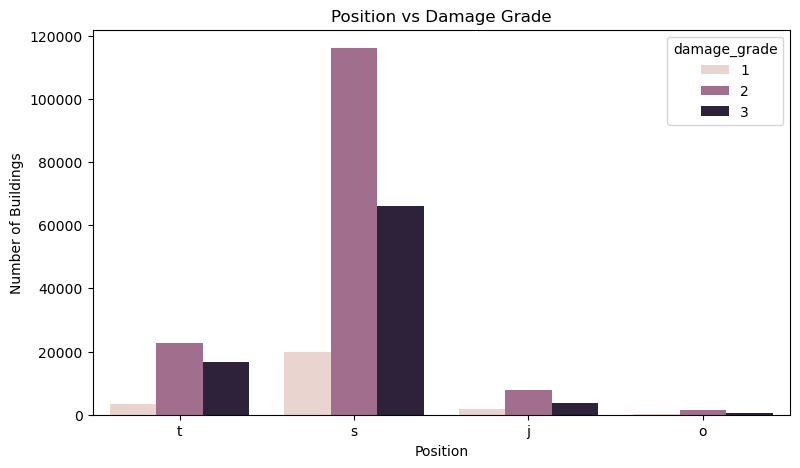

In [52]:
plt.figure(figsize=(9, 5))

sns.countplot(
    x="position",
    hue="damage_grade",
    data=df
)

plt.title("Position vs Damage Grade")
plt.xlabel("Position")
plt.ylabel("Number of Buildings")
plt.show()

For all position categories, Damage Grade 2 has the highest frequency. This indicates an association in the dataset, but it does not imply causation

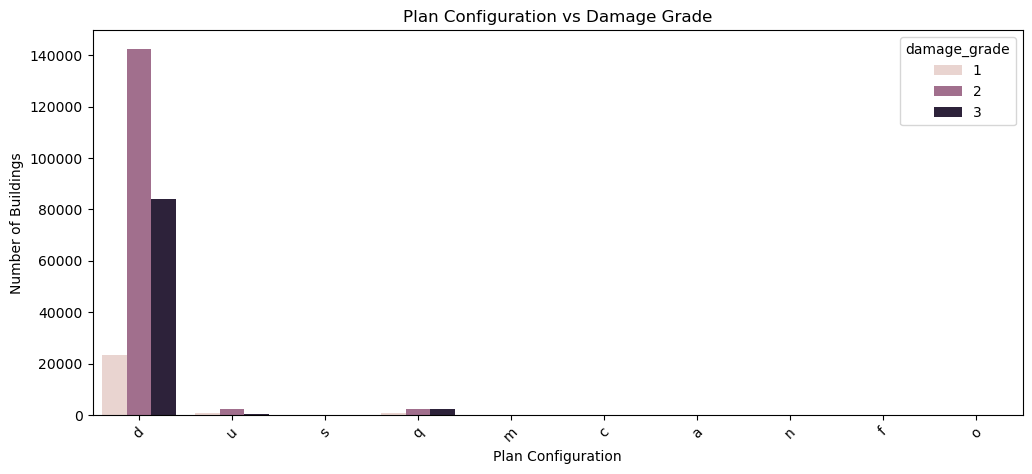

In [53]:
plt.figure(figsize=(12, 5))

sns.countplot(
    x="plan_configuration",
    hue="damage_grade",
    data=df
)

plt.title("Plan Configuration vs Damage Grade")
plt.xlabel("Plan Configuration")
plt.ylabel("Number of Buildings")
plt.xticks(rotation=45)
plt.show()

For categories d and u, Damage Grade 2 has the highest frequency. For category q, Damage Grades 2 and 3 have approximately similar frequencies

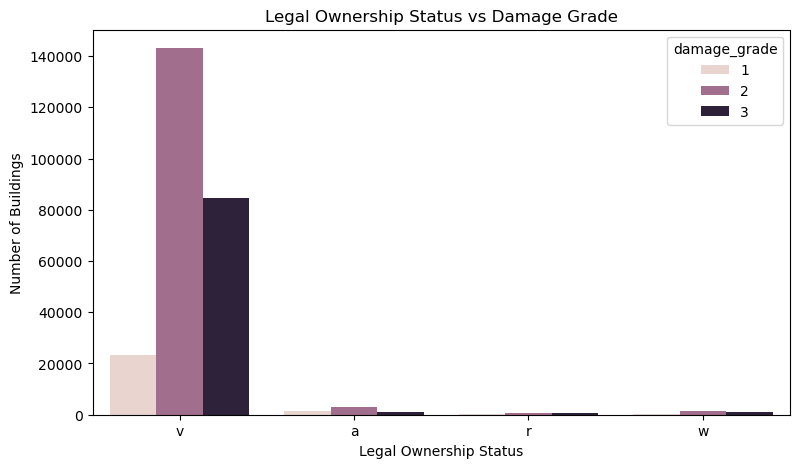

In [54]:
plt.figure(figsize=(9, 5))

sns.countplot(
    x="legal_ownership_status",
    hue="damage_grade",
    data=df
)

plt.title("Legal Ownership Status vs Damage Grade")
plt.xlabel("Legal Ownership Status")
plt.ylabel("Number of Buildings")
plt.show()

For categories v and a, Damage Grade 2 has the highest frequency. For categories r and w, Damage Grades 2 and 3 have approximately similar frequencies.

##  4: Bivariate Exploratory Data Analysis (EDA)

**Objective:** To understand the relationship between important features and the target variable `damage_grade`.

### Key Observations
1. **Number of floors:** Grade 2 has the highest frequency across most floor categories.
2. **Building age:** Higher damage grades show a relatively higher age distribution.
3. **Area percentage:** Grade 1 has a relatively higher median area percentage, but the distributions overlap.
4. **Height percentage:** Grade 3 shows a relatively higher median height percentage.
5. **Number of families:** The median is approximately one family across all damage grades.
6. **Foundation type:** Grade 2 is most frequent in categories `r`, `w`, and `u`.
7. **Roof type:** Grade 2 is most frequent in categories `n` and `q`.
8. **Ground floor type:** Grade 2 has the highest frequency across all observed categories.
9. **Other floor type:** Grade 2 is most frequent in categories `q`, `x`, and `j`.
10. **Position:** Grade 2 has the highest frequency across all observed categories.
11. **Plan configuration:** Grade 2 is most frequent in categories `d` and `u`.
12. **Legal ownership status:** Grade 2 is most frequent in categories `v` and `a`.

### Conclusion
Bivariate EDA was performed to explore relationships between numerical and categorical features and `damage_grade`. Grade 2 has the highest frequency in many categories. Some numerical features show differences across damage grades, while others have overlapping distributions.

These observations describe associations, not causation. Since category sizes differ, class proportions should also be checked before drawing strong conclusions.

## 5 — Feature Engineering & Preprocessing

In [55]:
#building_id → It is only ID , it does not useful for prediction 

df_model = df.drop("building_id", axis=1)
df_model

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,6,487,12198,2,30,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,3
1,8,900,2812,2,10,8,7,o,r,n,...,0,0,0,0,0,0,0,0,0,2
2,21,363,8973,2,10,5,5,t,r,n,...,0,0,0,0,0,0,0,0,0,3
3,22,418,10694,2,10,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,2
4,11,131,1488,3,30,8,9,t,r,n,...,0,0,0,0,0,0,0,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
260596,25,1335,1621,1,55,6,3,n,r,n,...,0,0,0,0,0,0,0,0,0,2
260597,17,715,2060,2,0,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,3
260598,17,51,8163,3,55,6,7,t,r,q,...,0,0,0,0,0,0,0,0,0,3
260599,26,39,1851,2,10,14,6,t,r,x,...,0,0,0,0,0,0,0,0,0,2


In [56]:
df_model.shape

(260601, 39)

## To separate Features and Target 
X = Features
y = Target

In [57]:
X = df_model.drop("damage_grade", axis=1)
Y = df_model["damage_grade"]

In [58]:
print("Features shape:", X.shape)
print("Target shape:", Y.shape)

Features shape: (260601, 38)
Target shape: (260601,)


##  identify  Numerical and categorical features 

In [59]:
numeric_features=X.select_dtypes(include=np.number).columns.tolist()
catogrical_features=X.select_dtypes(include="object").columns.tolist()
print("numerical_features:", len(numeric_features))
print("catogrical_features:",len(catogrical_features))


numerical_features: 30
catogrical_features: 8


## convert categorical features into numerical form

In [60]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [61]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), catogrical_features)
    ]
)

In [62]:
print("X shape:", X.shape)
print("y shape:", Y.shape)

X shape: (260601, 38)
y shape: (260601,)


In [63]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [64]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (208480, 38)
X_test: (52121, 38)
y_train: (208480,)
y_test: (52121,)


## Machine Learning model training

In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), catogrical_features)
    ]
)

In [66]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline= Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

In [67]:
logistic_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [68]:
y_pred = logistic_pipeline.predict(X_test)     #model predicted damage grade

In [69]:
y_pred[:10]      # 1st 10 prediction

array([3, 2, 2, 2, 2, 2, 2, 2, 3, 2])

In [70]:
from sklearn.metrics import accuracy_score

In [71]:
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.5920838049922296


In [72]:
print("Accuracy:",accuracy*100,"%")

Accuracy: 59.208380499222955 %


In [73]:
from sklearn.metrics import classification_report

In [74]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           1       0.56      0.29      0.39      5025
           2       0.60      0.87      0.71     29652
           3       0.55      0.20      0.29     17444

    accuracy                           0.59     52121
   macro avg       0.57      0.46      0.46     52121
weighted avg       0.58      0.59      0.54     52121



The Logistic Regression model achieved about 59.21% accuracy. It performed better for damage grade 2, with a recall of 87% and F1-score of 0.71. However, recall for grades 1 and 3 was low, especially grade 3 at 20%. This indicates that the model is not identifying the minority and severe-damage classes effectively

In [75]:
from sklearn.metrics import confusion_matrix

In [76]:
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[ 1472  3439   114]
 [ 1045 25904  2703]
 [   91 13869  3484]]


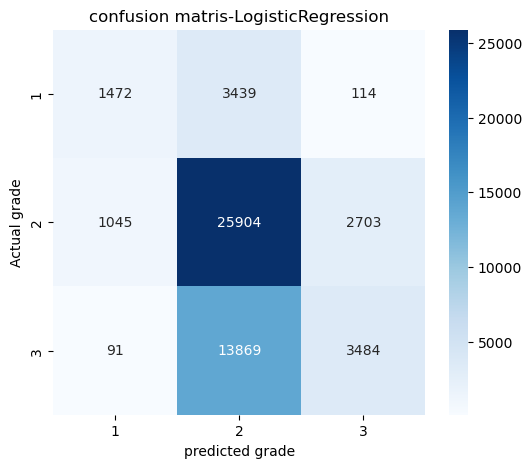

In [77]:
plt.figure(figsize=(6,5))

sns.heatmap(cm,
           annot=True,
           fmt="d",
           cmap="Blues",
           xticklabels=[1,2,3],
           yticklabels=[1,2,3],
)
plt.xlabel("predicted grade")
plt.ylabel("Actual grade")
plt.title("confusion matris-LogisticRegression")
plt.show()

### Confusion Matrix Interpretation

- Rows represent the actual damage grades.
- Columns represent the predicted damage grades.
- Diagonal values represent correct predictions.
- Off-diagonal values represent incorrect predictions.

The model predicts Damage Grade 2 relatively well.
However, many Grade 3 buildings are incorrectly predicted as Grade 2.
This shows that the Logistic Regression model has difficulty identifying severely damaged buildings.

#  6: Model Training and Evaluation

## Objective
Build and evaluate the first machine learning classification model
for predicting earthquake building damage grade.

## Model Used
Logistic Regression

## Steps Performed
1. Created Logistic Regression model.
2. Combined preprocessing and model using Pipeline.
3. Trained the model using training data.
4. Predicted damage grades on test data.
5. Evaluated the model using:
   - Accuracy
   - Precision
   - Recall
   - F1-score
   - Confusion Matrix

## Results

Accuracy = 59.21%

Classification Report:

- Grade 1: Precision = 0.56, Recall = 0.29, F1-score = 0.39
- Grade 2: Precision = 0.60, Recall = 0.87, F1-score = 0.71
- Grade 3: Precision = 0.55, Recall = 0.20, F1-score = 0.29

## Observation

The Logistic Regression model performs relatively well for Damage Grade 2.
However, it has difficulty identifying Damage Grade 1 and especially
Damage Grade 3.

Many actual Grade 3 buildings were incorrectly predicted as Grade 2.

Therefore, Logistic Regression is considered as a baseline model,
and other machine learning models will be compared to improve performance.

## Conclusion

Logistic Regression achieved 59.21% accuracy on the test dataset.
The classification report and confusion matrix show that the model
performs better for Grade 2 but struggles with the other damage grades.
Further models will be trained and compared to find a better-performing model.

In [78]:
# Decision Tree

In [79]:
from sklearn.tree import DecisionTreeClassifier

In [80]:
dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

In [81]:
dt_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("model",dt_model)
     ])

In [82]:
dt_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [83]:
y_pred_dt = dt_pipeline.predict(X_test)
y_pred_dt[:10]

array([2, 2, 3, 2, 3, 2, 2, 2, 2, 3])

In [84]:
dt_accuracy = accuracy_score(y_test,y_pred_dt)
print("Decision Tree accuracy:",dt_accuracy)
print("Decision Tree accuracy:",dt_accuracy * 100,"%")

Decision Tree accuracy: 0.6855969762667639
Decision Tree accuracy: 68.55969762667638 %


In [85]:
print(classification_report(y_test,y_pred_dt))

              precision    recall  f1-score   support

           1       0.61      0.40      0.49      5025
           2       0.69      0.81      0.75     29652
           3       0.68      0.56      0.61     17444

    accuracy                           0.69     52121
   macro avg       0.66      0.59      0.62     52121
weighted avg       0.68      0.69      0.68     52121



Model	              Accuracy	    Grade 3 Recall	    Grade 3 F1
Logistic Regression	   59.21%	        20%	                 0.29
Decision Tree	       68.56%	        56%	             0.61

“Decision Tree performed better than Logistic Regression. Its accuracy increased from 59.21% to 68.56%. More importantly, Grade 3 recall improved from 20% to 56%, indicating that Decision Tree identifies severely damaged buildings much better.”


In [86]:
cm_dt = confusion_matrix(y_test,y_pred_dt)
print(cm_dt)

[[ 2026  2918    81]
 [ 1215 24016  4421]
 [   70  7682  9692]]


### Decision Tree Confusion Matrix Interpretation

The confusion matrix compares the actual damage grades with the predicted damage grades.

| Actual / Predicted | Grade 1 | Grade 2 | Grade 3 |
|---|---:|---:|---:|
| Grade 1 | 2026 | 2918 | 81 |
| Grade 2 | 1215 | 24016 | 4421 |
| Grade 3 | 70 | 7682 | 9692 |

- 2,026 Grade 1 buildings were correctly predicted as Grade 1.
- 24,016 Grade 2 buildings were correctly predicted as Grade 2.
- 9,692 Grade 3 buildings were correctly predicted as Grade 3.
- The model incorrectly predicted 7,682 actual Grade 3 buildings as Grade 2.
- Overall, the Decision Tree performs better than Logistic Regression, especially for identifying Grade 3 buildings.

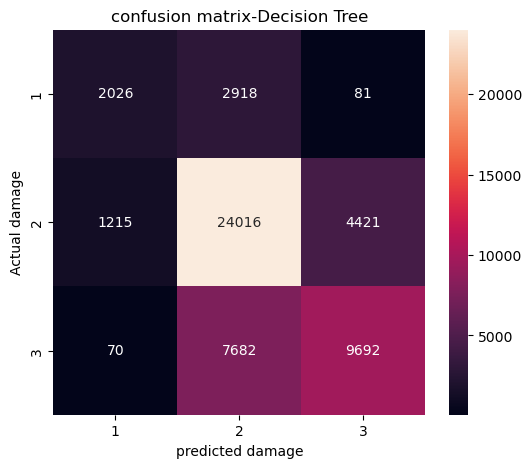

In [87]:
plt.figure(figsize=(6,5))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    xticklabels=[1,2,3],
    yticklabels=[1,2,3],
)
plt.xlabel("predicted damage")
plt.ylabel("Actual damage")
plt.title("confusion matrix-Decision Tree")
plt.show()

In [88]:
# Random Forest

In [89]:
from sklearn.ensemble import RandomForestClassifier

In [90]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

In [91]:
rf_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("model",rf_model)
])

In [92]:
rf_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [93]:
y_pred_rf =rf_pipeline.predict(X_test)
y_pred_rf[:10]

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [94]:
rf_accuracy = accuracy_score(y_test,y_pred_rf)
print("Random Forest Accuracy:",rf_accuracy)
print("Random Forest Accuracy:",rf_accuracy*100,"%")

Random Forest Accuracy: 0.6424281959287044
Random Forest Accuracy: 64.24281959287043 %


In [95]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           1       0.68      0.30      0.42      5025
           2       0.63      0.93      0.75     29652
           3       0.76      0.25      0.38     17444

    accuracy                           0.64     52121
   macro avg       0.69      0.49      0.51     52121
weighted avg       0.68      0.64      0.59     52121



In [96]:
cm_rf = confusion_matrix(y_test,y_pred_rf)
print("confusion matrix-Random Forest:")
print(cm_rf)

confusion matrix-Random Forest:
[[ 1503  3496    26]
 [  678 27607  1367]
 [   35 13035  4374]]


### Random Forest Confusion Matrix Interpretation

The confusion matrix shows that the Random Forest model correctly
classified 1,503 Grade 1, 27,607 Grade 2, and 4,374 Grade 3 buildings.

The model performs well in identifying Grade 2 buildings. However,
a large number of actual Grade 3 buildings (13,035) were incorrectly
classified as Grade 2.

Therefore, the Random Forest model still has difficulty identifying
severely damaged buildings.

#  7: Model Comparison

## Objective
Train and compare multiple machine learning classification models
for predicting earthquake building damage grade.

## Models Used
1. Logistic Regression
2. Decision Tree
3. Random Forest

## Model Performance

| Model | Accuracy | Grade 3 Recall |
|---|---:|---:|
| Logistic Regression | 59.21% | 20% |
| Decision Tree | 68.56% | 56% |
| Random Forest | 64.24% | 25% |

## Observations

- Logistic Regression achieved 59.21% accuracy.
- Decision Tree achieved the highest accuracy of 68.56%.
- Random Forest achieved 64.24% accuracy.
- Decision Tree also achieved the highest Grade 3 recall of 56%.
- All models performed best on Grade 2, which is the majority class.
- Identifying Grade 3 buildings remains challenging for the models.

## Conclusion

Among the three models tested so far, the Decision Tree
performed best based on accuracy and Grade 3 recall.

However, the final model will not be selected yet.
Further models and hyperparameter tuning will be performed
before selecting the final production model.

In [97]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC


In [98]:
linear_svm_model = LinearSVC(
    C=1.0,
    max_iter=3000,
    random_state=42
)

In [99]:
linear_svm_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("model",linear_svm_model)
])

In [100]:
linear_svm_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [101]:
y_pred_svm = linear_svm_pipeline.predict(X_test)
y_pred_svm[:10]

array([2, 2, 2, 2, 2, 2, 2, 2, 3, 2])

In [102]:
Accuracy = accuracy_score(y_test,y_pred_svm)
print("Accuracy:", Accuracy)
print("Accuracy:",Accuracy*100,"%")

Accuracy: 0.5903570537787073
Accuracy: 59.03570537787073 %


In [103]:
print(classification_report(y_test,y_pred_svm))

              precision    recall  f1-score   support

           1       0.59      0.22      0.32      5025
           2       0.59      0.90      0.72     29652
           3       0.56      0.17      0.26     17444

    accuracy                           0.59     52121
   macro avg       0.58      0.43      0.43     52121
weighted avg       0.58      0.59      0.52     52121



### LinearSVC Classification Report

LinearSVC achieved 59.04% accuracy.

The model performed relatively well for Damage Grade 2, with a
recall of 90%. However, it achieved only 22% recall for Grade 1
and 17% recall for Grade 3.

The model struggled to identify severely damaged buildings.
Therefore, its performance will be compared with other models
before selecting the final model.

In [104]:
cm_svm = confusion_matrix(y_test,y_pred_svm)
print("linearSVC confusion mtrix")
print(cm_svm)

linearSVC confusion mtrix
[[ 1113  3797   115]
 [  721 26776  2155]
 [   42 14521  2881]]


### LinearSVC Confusion Matrix Interpretation

The confusion matrix shows that LinearSVC correctly classified
1,113 Grade 1, 26,776 Grade 2, and 2,881 Grade 3 buildings.

The model performed relatively well for Grade 2 but struggled
to identify Grade 3 buildings. A total of 14,521 actual Grade 3
buildings were incorrectly classified as Grade 2.

Therefore, LinearSVC requires comparison with other models
before selecting the final model.

In [105]:
# K-Nearest Neighbors (KNN)

In [106]:
from sklearn.neighbors import KNeighborsClassifier


In [107]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

In [108]:
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", knn_model)
])

In [109]:
knn_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [110]:
y_pred_knn= knn_pipeline.predict(X_test)
y_pred_knn[:10]

array([3, 2, 2, 2, 2, 3, 3, 2, 3, 2])

In [111]:
Accuracy = accuracy_score(y_test,y_pred_knn)
print("Accuracy:",Accuracy)
print("Accuracy:", Accuracy*100,"%")

Accuracy: 0.6550334797874178
Accuracy: 65.50334797874177 %


In [112]:
print(classification_report(y_test,y_pred_knn))

              precision    recall  f1-score   support

           1       0.52      0.48      0.50      5025
           2       0.69      0.75      0.72     29652
           3       0.62      0.55      0.58     17444

    accuracy                           0.66     52121
   macro avg       0.61      0.59      0.60     52121
weighted avg       0.65      0.66      0.65     52121



### KNN Classification Report

The KNN model achieved 65.50% accuracy.

It achieved recall scores of 48% for Grade 1, 75% for Grade 2,
and 55% for Grade 3.

The model showed a better balance across the three damage grades
than some of the earlier models. However, it still missed a
significant number of damaged buildings.

Its performance will be compared with other models before
selecting the final model.

In [113]:
cm_knn= confusion_matrix(y_test,y_pred_knn)
print("confusion matrix - knn")
print(cm_knn)

confusion matrix - knn
[[ 2392  2398   235]
 [ 1953 22182  5517]
 [  278  7599  9567]]


#  8: Additional Model Building and Evaluation

## Objective
Train and evaluate additional classification models for earthquake damage prediction.

## Models Used
1. LinearSVC
2. K-Nearest Neighbors (KNN)

## Results
- LinearSVC achieved 59.04% accuracy.
- KNN achieved 65.50% accuracy.
- KNN performed better than LinearSVC in overall accuracy and Grade 3 recall.
- Decision Tree remains the best-performing model so far based on accuracy.

## Conclusion
The additional models were evaluated using accuracy, classification reports, and confusion matrices. KNN performed better than LinearSVC, particularly in identifying Grade 3 buildings. Further model comparison and hyperparameter tuning are required before selecting the final model.

## 9: Model Evaluation & Comparison

In [114]:
from sklearn.metrics import accuracy_score,classification_report
import pandas as pd

# Predictions from all five trained models
model_predictions = {
    "logisticRegression":y_pred,
    "DecisionTree":y_pred_dt,
    "RandomForest":y_pred_rf,
    "SVM":y_pred_svm,
    "KNN":y_pred_knn
}

comparison_rows=[]

for model_name,predictions in model_predictions.items():
    report= classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    comparison_rows.append({
        "model":model_name,
        "Accuracy":accuracy_score(y_test,predictions),
        "macro f1":report["macro avg"]["f1-score"],
        "Grade 1 recall":report["1"]["recall"],
        "Grade 2 recall":report["2"]["recall"],
        "Grade 3 recall":report["3"]["recall"]
            })

comparison_df= pd.DataFrame(comparison_rows)

comparison_df=comparison_df.sort_values(
    by="Accuracy",
    ascending=False
)

comparison_df.round(3)

,model,Accuracy,macro f1,Grade 1 recall,Grade 2 recall,Grade 3 recall
1,DecisionTree,0.686,0.615,0.403,0.810,0.556
4,KNN,0.655,0.599,0.476,0.748,0.548
2,RandomForest,0.642,0.513,0.299,0.931,0.251
0,logisticRegression,0.592,0.463,0.293,0.874,0.200
3,SVM,0.590,0.431,0.221,0.903,0.165




### Objective
To improve the Decision Tree model by testing different hyperparameter combinations and selecting the best configuration using cross-validation.


In [115]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection  import GridSearchCV

In [116]:
print("Imports completed successfully")

Imports completed successfully


In [117]:
dt_pipeline_tuning=Pipeline([
    ("preprocessor",preprocessor),
    ("model",DecisionTreeClassifier(random_state=42))
])

param_grid = {
    "model__max_depth": [5, 10, 15],
    "model__min_samples_split": [2, 10],
    "model__min_samples_leaf": [1, 5]
}
grid_search= GridSearchCV(
    estimator=dt_pipeline_tuning,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train,y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 5], 'model__min_samples_split': [2, 10]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [118]:
print("Best hyperparameters:",grid_search.best_params_)
print("Best F1 score:", grid_search.best_score_)

Best hyperparameters: {'model__max_depth': 15, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Best F1 score: 0.627532850347556


In [119]:
best_dt_model=grid_search.best_estimator_
y_pred_tuned= best_dt_model.predict(X_test)
from sklearn.metrics import accuracy_score,classification_report
tuned_accuracy=accuracy_score(y_test,y_pred_tuned)
print("Tuned Decision Tree Accuracy:", tuned_accuracy)
print("\n classification report:")
print(classification_report(y_test,y_pred_tuned,zero_division=0))

Tuned Decision Tree Accuracy: 0.7045912396155101

 classification report:
              precision    recall  f1-score   support

           1       0.60      0.45      0.51      5025
           2       0.72      0.81      0.76     29652
           3       0.70      0.60      0.65     17444

    accuracy                           0.70     52121
   macro avg       0.67      0.62      0.64     52121
weighted avg       0.70      0.70      0.70     52121



## 10: Hyperparameter Tuning

### Objective
To improve the Decision Tree classifier by using GridSearchCV and selecting the best hyperparameters.

### Best Hyperparameters
- max_depth: 15
- min_samples_leaf: 5
- min_samples_split: 2

### Results
- Best cross-validation Macro F1-score: 0.6275
- Test accuracy: 70.46%
- Test Macro F1-score: approximately 0.64
- Grade 3 recall: 60%

### Conclusion
Hyperparameter tuning improved the Decision Tree model's accuracy from approximately 68.56% to 70.46%. Grade 3 recall also improved from approximately 55.6% to 60%. The tuned model performs better than the original Decision Tree on the current test evaluation. Further analysis is required before final model selection.


## Final Model Comparison (After Hyperparameter Tuning)

In [120]:
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Predictions from all six models
model_predictions = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Linear SVM": y_pred_svm,
    "KNN": y_pred_knn,
    "Tuned Decision Tree": y_pred_tuned
}

comparison_rows = []

for model_name, predictions in model_predictions.items():

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1-Score": report["macro avg"]["f1-score"],
        "Grade 1 Recall": report["1"]["recall"],
        "Grade 2 Recall": report["2"]["recall"],
        "Grade 3 Recall": report["3"]["recall"]
    })

# Create comparison DataFrame
comparison_df = pd.DataFrame(comparison_rows)

# Sort models by accuracy
comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

# Display comparison table
comparison_df.round(3)

,Model,Accuracy,Macro F1-Score,Grade 1 Recall,Grade 2 Recall,Grade 3 Recall
0,Tuned Decision Tree,0.705,0.641,0.449,0.809,0.602
1,Decision Tree,0.686,0.615,0.403,0.810,0.556
2,KNN,0.655,0.599,0.476,0.748,0.548
3,Random Forest,0.642,0.513,0.299,0.931,0.251
4,Logistic Regression,0.592,0.463,0.293,0.874,0.200
5,Linear SVM,0.590,0.431,0.221,0.903,0.165


## Feature Importance

In [121]:
# Get the trained Decision Tree from the tuned pipeline
best_tree = best_dt_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = best_dt_model.named_steps["preprocessor"].get_feature_names_out()

# Create a feature importance table
Importance_df=pd.DataFrame({
    "feature":feature_names,
    "Importance":best_tree.feature_importances_
})

# Sort features from most to least important
Importance_df= Importance_df.sort_values(
    by="Importance",
    ascending=False
)

Importance_df.head(15)

,feature,Importance
0,num__geo_level_1_id,0.368110
1,num__geo_level_2_id,0.170028
35,cat__foundation_type_r,0.107089
2,num__geo_level_3_id,0.071826
4,num__age,0.042105
5,num__area_percentage,0.037624
8,num__has_superstructure_mud_mortar_stone,0.037501
6,num__height_percentage,0.022483
47,cat__other_floor_type_q,0.011349
34,cat__foundation_type_i,0.011025


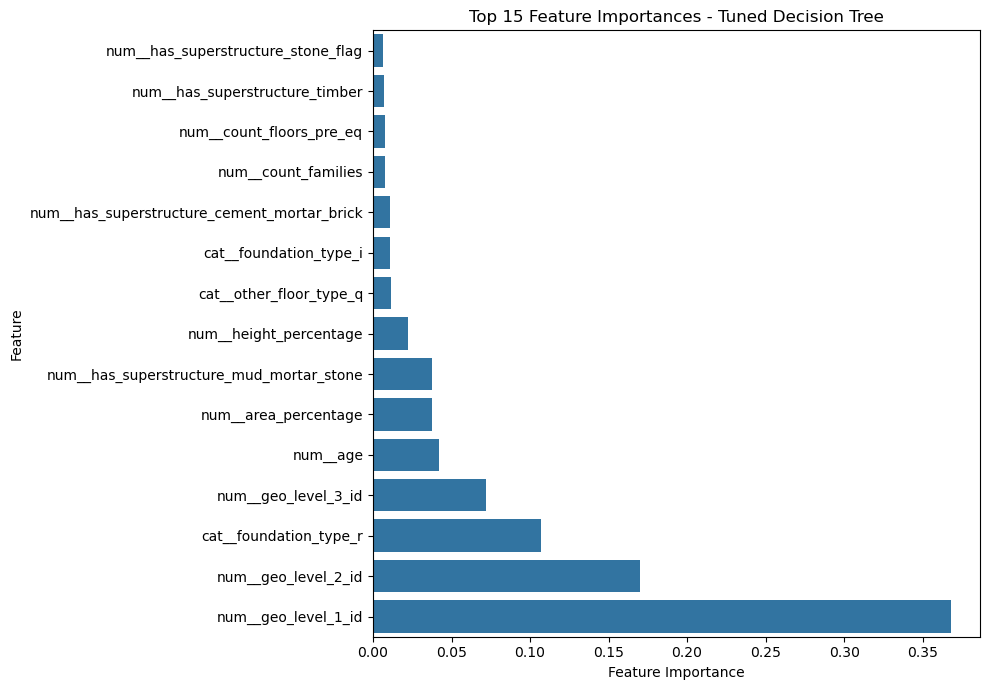

In [122]:

top_features = Importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="feature"
)

plt.title("Top 15 Feature Importances - Tuned Decision Tree")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



### Objective
To identify the features that contribute most to the tuned Decision Tree's predictions.

### Observations
- geo_level_1_id had the highest feature importance (approximately 0.368).
- geo_level_2_id was the second most important feature (approximately 0.170).
- foundation_type_r ranked third (approximately 0.107).
- geo_level_3_id, age, and area_percentage were also among the important features.

### Conclusion
The tuned Decision Tree relied heavily on geographic identifiers and certain building-related features. Feature importance indicates predictive usefulness, not causation.


##  12: Recommendations for Seismologists

### 1. Identify Risky Buildings
Our model can help identify buildings that may face severe earthquake damage.

### 2. Check Buildings
Buildings predicted to have severe damage should be inspected by experts.

### 3. Study Building Features
We should study building age, foundation type, height, and area to understand damage patterns.

### 4. Study Locations
Our model found geographic features important. Experts should study damage patterns in different locations.

### 5. Improve Safety
Use the findings to support earthquake preparedness and building safety planning.

### Conclusion
Our Decision Tree model achieved 70.46% accuracy and 60% recall for Grade 3. It can support risk assessment, but expert inspections are necessary before making safety decisions.




## 13: Challenges Faced

### 1. Imbalanced Data
Damage Grade 2 had more observations than Grades 1 and 3. Therefore, accuracy alone was not sufficient to evaluate model performance. We also compared Macro F1-score and class-wise recall.

### 2. Categorical Feature Encoding
The dataset contained categorical features. We used OneHotEncoder to convert them into numerical features for machine learning models.

### 3. Model Performance
Some models struggled to identify severely damaged buildings (Grade 3). We compared class-wise recall and used hyperparameter tuning to improve the Decision Tree model.

### 4. Training Time
Training the RBF SVM model took too long on the full dataset. We stopped that run and evaluated LinearSVC as an alternative.

### 5. Feature Interpretation
Geographic identifiers and encoded categories were difficult to interpret directly. Feature importance was used to identify predictive features, while avoiding assumptions about causation.

### 6. Hyperparameter Tuning
We used GridSearchCV with three-fold cross-validation to compare Decision Tree hyperparameters and select a configuration using Macro F1-score.

## Conclusion

This project developed a machine learning model to predict building damage grades caused by earthquakes.

Five classification models were initially compared, and the Decision Tree performed best among the initial models. After hyperparameter tuning, the tuned Decision Tree achieved an accuracy of **70.46%**, a Macro F1-score of approximately **0.64**, and a **60% recall for Grade 3** (severe damage).

Feature importance analysis identified geographic ID features and foundation type as important predictors of building damage grades. These findings may help support building risk assessment and disaster preparedness.

However, the model does not identify every severely damaged building correctly. Further validation on independent data and expert inspection are necessary before using its predictions for real-world safety decisions.